In [15]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as pl
from Bio import SeqIO
from tqdm.auto import tqdm

In [4]:
def hamming_distance(s1, s2):
    return sum(a != b for a, b in zip(s1, s2))

def is_true_mismatch(base1, base2, qual, qual_threshold):
    if base1 != base2 and qual >= qual_threshold:
        return True
    return False

In [67]:
max_effective_mismatches = 1
max_mismatches = 3
quality_threshold = 30

barcodes = pd.read_csv('../resources/library/sym_hepa_library_map.csv', index_col="barcode").guide_name.to_dict()
for sample in ["Hepa-library-1_S10", "Hepa-library-2_S11", "Hepa-library-3_S12"]:
    res = {}
    unmatched = []
    for record in tqdm(SeqIO.parse(f"/home/peidli/projects/symphony-hepatocytes/scratch/trimmed/{sample}_barcodes.fastq", "fastq")):
        qual = record.letter_annotations["phred_quality"]
        seq = str(record.seq)
        best_match = None
        for barcode in barcodes.keys():
            mismatches = hamming_distance(seq, barcode)
            if mismatches > max_mismatches:
                continue  # Skip, too many mismatches mismatches)
            effective_mismatches = sum(
                    is_true_mismatch(a, b, q, quality_threshold)
                    for a, b, q in zip(seq, barcode, qual)
                )
            if effective_mismatches > max_effective_mismatches:
                continue  # Skip, too many effective mismatches
            if best_match is None or (mismatches, effective_mismatches) < (best_match[1], best_match[2]):
                best_match = (barcode, mismatches, effective_mismatches)
        if best_match:
            res[record.id] = best_match
        else:
            unmatched.append(record.id)
    res_df = pd.DataFrame.from_dict(res, orient='index', columns=['barcode', 'mismatches', 'effective_mismatches'])
    res_df.to_csv(f'{sample}_barcode_counts.csv')
    unmatched_df = pd.DataFrame(unmatched, columns=['read_id'])
    unmatched_df.to_csv(f'{sample}_barcode_unmatched_reads.csv', index=False)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [39]:
len(res), len(unmatched)

(49753, 10738)

In [68]:
max_effective_mismatches = 1
max_mismatches = 3
quality_threshold = 30

guides = pd.read_csv('../resources/library/sym_hepa_library_map.csv', index_col="gRNA").guide_name.to_dict()
for sample in ["Hepa-library-1_S10", "Hepa-library-2_S11", "Hepa-library-3_S12"]:
    res = {}
    unmatched = []
    for record in tqdm(SeqIO.parse(f"/home/peidli/projects/symphony-hepatocytes/scratch/trimmed/{sample}_guides.fastq", "fastq")):
        qual = record.letter_annotations["phred_quality"]
        seq = str(record.seq)
        best_match = None
        for guide in guides.keys():
            mismatches = hamming_distance(seq, guide)
            if mismatches > max_mismatches:
                continue  # Skip, too many mismatches mismatches)
            effective_mismatches = sum(
                    is_true_mismatch(a, b, q, quality_threshold)
                    for a, b, q in zip(seq, guide, qual)
                )
            if effective_mismatches > max_effective_mismatches:
                continue  # Skip, too many effective mismatches
            if best_match is None or (mismatches, effective_mismatches) < (best_match[1], best_match[2]):
                best_match = (guide, mismatches, effective_mismatches)
        if best_match:
            res[record.id] = best_match
        else:
            unmatched.append(record.id)
    res_df = pd.DataFrame.from_dict(res, orient='index', columns=['guide', 'mismatches', 'effective_mismatches'])
    res_df.to_csv(f'{sample}_guide_counts.csv')
    unmatched_df = pd.DataFrame(unmatched, columns=['read_id'])
    unmatched_df.to_csv(f'{sample}_guide_unmatched_reads.csv', index=False)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [69]:
len(res), len(unmatched)

(51347, 9144)

In [92]:
9144/51347

0.17808245856622587

# Merging

In [93]:
unmatched_guides

,read_id
0,M02088:83:000000000-LY4KK:1:1101:17181:1854
1,M02088:83:000000000-LY4KK:1:1101:21227:3957
2,M02088:83:000000000-LY4KK:1:1101:15227:4065
3,M02088:83:000000000-LY4KK:1:1101:9278:4470
4,M02088:83:000000000-LY4KK:1:1101:12995:4563
...,...
9139,M02088:83:000000000-LY4KK:1:2114:14110:28464
9140,M02088:83:000000000-LY4KK:1:2114:12421:28590
9141,M02088:83:000000000-LY4KK:1:2114:14404:28683
9142,M02088:83:000000000-LY4KK:1:2114:14703:29040


In [98]:
read_dfs = {}
for sample in ["Hepa-library-1_S10", "Hepa-library-2_S11", "Hepa-library-3_S12"]:
    guide_df = pd.read_csv(f'{sample}_guide_counts.csv', index_col=0)
    barcode_df = pd.read_csv(f'{sample}_barcode_counts.csv', index_col=0)
    unmatched_guides = pd.read_csv(f'{sample}_guide_unmatched_reads.csv')
    unmatched_barcodes = pd.read_csv(f'{sample}_barcode_unmatched_reads.csv')
    read_df = pd.merge(guide_df, barcode_df, left_index=True, right_index=True, how='outer', suffixes=('_guide', '_barcode'))
    # add unmatched reads
    read_df = pd.concat([
        read_df,
        pd.DataFrame(index=unmatched_guides.read_id).assign(guide=None, mismatches_guide=None, effective_mismatches_guide=None, barcode=None, mismatches_barcode=None, effective_mismatches_barcode=None),
        pd.DataFrame(index=unmatched_barcodes.read_id).assign(guide=None, mismatches_guide=None, effective_mismatches_guide=None, barcode=None, mismatches_barcode=None, effective_mismatches_barcode=None),
    ])
    read_dfs[sample] = read_df
read_df = pd.concat(read_dfs)

/tmp/ipykernel_2178148/1079598432.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  read_df = pd.concat([
/tmp/ipykernel_2178148/1079598432.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  read_df = pd.concat([
/tmp/ipykernel_2178148/1079598432.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude 

In [99]:
read_df['guide_says'] = read_df.guide.map(guides)
read_df['barcode_says'] = read_df.barcode.map(barcodes)
read_df['read_type'] = ['matching_guide_and_barcode' if g == b else
                        'mismatched_guide_and_barcode' if pd.notna(g) and pd.notna(b) else
                        'guide_only' if pd.notna(g) else
                        'barcode_only' if pd.notna(b) else
                        'unmapped' for g, b in zip(read_df['guide_says'], read_df['barcode_says'])]
read_df.reset_index(level=0, names='sample', inplace=True)

/tmp/ipykernel_2178148/704984389.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([rename[t.get_text()] for t in ax.get_yticklabels()])


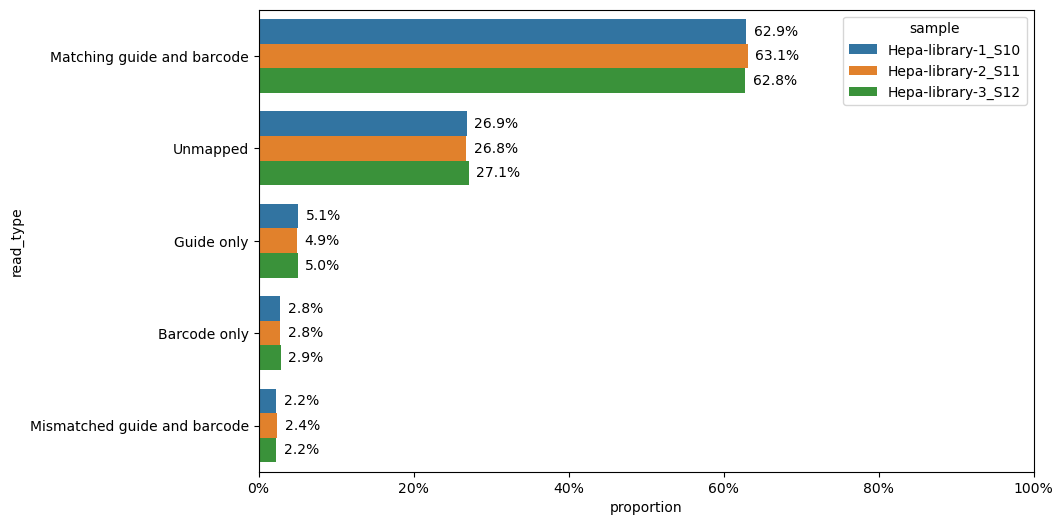

In [ ]:
cts = read_df[['sample', 'read_type']].value_counts()
cts = cts.divide(cts.groupby(level=0).sum(), level=0)  # proportions
cts.name = 'proportion'
cts = cts.reset_index()
fig, ax = pl.subplots(figsize=(10, 6))
sns.barplot(data=cts, y='read_type', x='proportion', hue='sample')
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
# add percentage labels to bars
for p in ax.patches:
    width = p.get_width()
    if width > 0.0000001:
        ax.text(width + 0.01, p.get_y() + p.get_height() / 2,
                f'{width:.1%}', ha='left', va='center')
ax.set_xlim(0, 1)
rename = {
    'matching_guide_and_barcode': 'Matching guide and barcode',
    'mismatched_guide_and_barcode': 'Mismatched guide and barcode',
    'guide_only': 'Guide only',
    'barcode_only': 'Barcode only',
    'unmapped': 'Unmapped',
}
ax.set_yticklabels([rename[t.get_text()] for t in ax.get_yticklabels()])
pl.show()

In [86]:
cts

,sample,read_type,count
0,Hepa-library-1_S10,matching_guide_and_barcode,0.860369
1,Hepa-library-2_S11,matching_guide_and_barcode,0.862097
2,Hepa-library-3_S12,matching_guide_and_barcode,0.861091
3,Hepa-library-1_S10,guide_only,0.070378
4,Hepa-library-2_S11,guide_only,0.067185
5,Hepa-library-3_S12,guide_only,0.069080
6,Hepa-library-1_S10,barcode_only,0.038674
7,Hepa-library-2_S11,barcode_only,0.038358
8,Hepa-library-3_S12,barcode_only,0.039255
9,Hepa-library-1_S10,mismatched_guide_and_barcode,0.030578
